# MATI 2026-27. Trabajo. Problema del Viajante (TSP) sobre la red de carreteras de España

*Datos © [OpenStreetMap contributors](https://www.openstreetmap.org/copyright), distribuidos con licencia [ODbL](https://opendatacommons.org/licenses/odbl/). Extracto de España publicado por [Geofabrik](https://download.geofabrik.de/europe/spain.html). Población: [INE](https://www.ine.es). Se mantiene la atribución, como es obligatorio.*

El objetivo del trabajo es **modelar la red de carreteras de la España peninsular como un grafo** y evaluar el rendimiento de varios algoritmos para resolver el **Problema del Viajante (TSP)** sobre distintas selecciones de ciudades (las capitales peninsulares, las ciudades de más de 100.000 habitantes...).

**Índice**

1. Construcción del grafo de la red vial peninsular
2. Versiones del grafo: carreteras, ciudades, pesos y tipo de grafo
3. Algoritmos para el Problema del Viajante: teoría y eficiencia *(pendiente)*
4. Estudio experimental de la eficiencia de los algoritmos *(pendiente)*
5. Conclusiones *(pendiente)*

> 📎 **Anexos.** El código que descarga los datos y construye el grafo **no está en este notebook**: se entrega aparte, como **Anexo A** (`anexos/descargar_red.py`) y **Anexo B** (`anexos/construir_grafo.py`), junto con el archivo del grafo `data/espana_red_maestra_secundarias.graphml` y la lista de ciudades `data/ciudades.csv`.

> 🕸️ **Librería de grafos.** Se usa **NetworkX**, la misma que en las prácticas. El grafo se carga directamente con `nx.read_graphml`. [OSMnx](https://osmnx.readthedocs.io) solo interviene en el Anexo B para construirlo.

> ⚙️ **Entorno:** para ejecutar este notebook bastan `networkx`, `numpy`, `scipy` y `matplotlib` (ver `requirements.txt`), que ya están en el entorno `Python (MATI .venv)` de las prácticas.

> ⏭️ **¿Solo vas a trabajar con las versiones ya calculadas?** (por ejemplo, para programar los algoritmos de las Partes 3 y 4). Entonces **no necesitas el grafo grande**: salta la Parte 1 y ejecuta desde la **Parte 2**. Las tablas ya calculadas están en `data/versiones/` y la celda que las calcula no se ejecuta si ya existen.

In [1]:
# Librerías que se usan en todo el notebook
import csv                       # leer y escribir tablas en formato CSV
import itertools                 # recorrer todas las combinaciones de parámetros
import unicodedata               # quitar acentos de los nombres (Cataluña -> cataluna)
from pathlib import Path         # rutas de archivos

import networkx as nx            # crear y analizar grafos (la misma librería de las prácticas)
import numpy as np               # tablas de números (las tablas de distancias)
from scipy.sparse import csr_matrix                 # matriz del grafo para el algoritmo de Dijkstra
from scipy.sparse.csgraph import dijkstra           # caminos mínimos desde varios orígenes
from scipy.spatial import cKDTree                   # buscar rápido el nodo más cercano a un punto

from tsp_utils import dibujar_red  # función de dibujo de la red de carreteras, comentada en tsp_utils.py

---

## Parte 1. Construcción del grafo de la red vial peninsular

<div style="border-left:5px solid #888;background:#F2F2F2;padding:10px 14px;margin:10px 0;border-radius:4px;">

**📋 ENUNCIADO**

Construir el **grafo de la red de carreteras de la España peninsular** que servirá de base al resto del trabajo: una única red "maestra", obtenida una sola vez, guardada en un archivo local y sobre la que se calcularán después las distancias y los tiempos entre ciudades.

Requisitos:

- **Ámbito:** España peninsular. Se excluyen las islas (Baleares y Canarias) y los enclaves que romperían la continuidad terrestre.
- **Carreteras:** como mínimo hasta el nivel de la red primaria. Se incluye además la red secundaria, para poder estudiar también redes sin autovías (ver la Resolución) y obtener después versiones más pequeñas filtrando aristas.
- **Atributos por tramo:** longitud en metros (`length`) y tiempo de viaje en segundos (`travel_time`).
- **Almacenamiento:** archivo local `data/espana_red_maestra_secundarias.graphml`, comprobando que se puede volver a leer sin errores.

*[Pendiente: sustituir este resumen por el enunciado literal del trabajo.]*

</div>

<div style="border-left:5px solid #4C72B0;background:#EEF2FA;padding:10px 14px;margin:10px 0;border-radius:4px;">

**📚 TEORÍA**

**Grafo de carreteras.** Una red de carreteras se representa como un **grafo**: los **nodos** son las intersecciones (y los extremos de carretera) y las **aristas** son los tramos de carretera que las unen. Como hay vías de sentido único, el grafo es **dirigido**: una carretera de doble sentido se representa con *dos* aristas, una por cada dirección. Y es **ponderado**: cada arista lleva asociados una longitud y un tiempo.

Formalmente, $G=(V,E)$ con $V$ el conjunto de nodos y $E\subseteq V\times V$ el de aristas dirigidas, y dos funciones de peso $\ell, t : E \to \mathbb{R}_{>0}$:

$$\ell(e) = \text{longitud en metros},\qquad t(e)=\frac{\ell(e)}{v(e)}\quad\text{con } v(e)=\frac{v_{\text{km/h}}(e)}{3.6}\ \text{m/s}.$$

**Una arista es un tramo entero.** Los puntos intermedios de una carretera (sin cruces) no aportan información para calcular rutas, así que se **funden**: cada arista une dos intersecciones y su longitud es la de todo el tramo. El grafo es mucho más pequeño y las distancias no cambian.

**Multigrafo.** Puede haber varias carreteras distintas entre las mismas dos intersecciones, así que el grafo admite **aristas paralelas**: es un `nx.MultiDiGraph`. Cada arista se identifica con la terna $(u, v, \text{clave})$.

**Conectividad fuerte.** Un grafo dirigido es **fuertemente conexo** si para todo par de nodos $u, v$ existe un camino dirigido de $u$ a $v$. Es imprescindible para el TSP: garantiza que se puede llegar de cualquier ciudad a cualquier otra respetando los sentidos de circulación.

</div>

<div style="border-left:5px solid #8172B2;background:#F1EEF9;padding:10px 14px;margin:10px 0;border-radius:4px;">

**🔢 DATOS**

| Dato | Valor |
|---|---|
| Fuente | OpenStreetMap, extracto de España de Geofabrik (`spain-latest.osm.pbf`, ≈ 1,4 GB, del 19/10/2026) |
| Tipos de vía (`highway`) | `motorway`, `trunk`, `primary` y `secondary`, con sus enlaces `_link` |
| Ámbito | España peninsular (sin Baleares, Canarias, Ceuta ni Melilla) |
| Peso en metros | `length` (a partir de la geometría de OpenStreetMap) |
| Peso en segundos | `travel_time` = `length` / velocidad |
| Velocidad | velocidad máxima de OpenStreetMap; si falta, la media de su tipo de vía |
| Archivo del grafo | `data/espana_red_maestra_secundarias.graphml` (108 MB) |
| Código | Anexo A `anexos/descargar_red.py` y Anexo B `anexos/construir_grafo.py` |

</div>

<div style="border-left:5px solid #55A868;background:#EAF6ED;padding:10px 14px;margin:10px 0;border-radius:4px;">

**🧮 RESOLUCIÓN — Cómo se ha obtenido el grafo**

**Origen de los datos.** [OpenStreetMap](https://www.openstreetmap.org) (OSM) es un mapa colaborativo del mundo; **no es una fuente oficial**, aunque es una referencia habitual. [Geofabrik](https://download.geofabrik.de/europe/spain.html) publica cada día un **extracto** con todos los datos de España en un único archivo `spain-latest.osm.pbf` (formato binario comprimido de OSM, ≈ 1,4 GB). Se ha usado el del 19/10/2026.

**Descarga — Anexo A (`anexos/descargar_red.py`).** Descarga ese archivo a la carpeta `data/`. Si se corta la conexión, la descarga se reanuda donde se quedó (≈ 7 min en una conexión normal). Si el grafo ya existe, el script lo avisa y no descarga nada.

**Construcción — Anexo B (`anexos/construir_grafo.py`).** Convierte el extracto en el grafo en cinco pasos (≈ 4 min y ≈ 2,3 GB de memoria):

1. **Leer** del extracto las carreteras de tipo `motorway`, `trunk`, `primary` y `secondary` (y sus enlaces) y las coordenadas de sus nodos.
2. **Construir** el grafo dirigido: cada carretera de sentido único da una arista y cada una de doble sentido da dos.
3. **Quedarse con la península:** se conserva la mayor componente conexa, y las islas, Ceuta y Melilla desaparecen por ser pequeñas componentes desconectadas. Después se **simplifica** (se funden los tramos entre intersecciones) y se garantiza la **conectividad fuerte**.
4. **Calcular los pesos:** `length` en metros, `speed_kph` (la velocidad máxima etiquetada en OSM o, si falta, la media de su tipo de vía) y `travel_time` en segundos. Se descartan los atributos que no se van a usar.
5. **Guardar** en GraphML y **comprobar** que se puede volver a leer con tipos correctos.

**¿Por qué incluir las carreteras secundarias?** Con solo autovías, vías rápidas y carreteras principales, una red *sin autovías* (por ejemplo, para ir en bici) queda llena de agujeros: Almería a 142 km de la red y Madrid–Sevilla con 761 km en lugar de 510. Con las secundarias, esa red es utilizable. Las versiones más pequeñas (por ejemplo, sin secundarias) se obtienen después **filtrando aristas** de este grafo (Parte 2). Con la opción `--ligero` el Anexo B construye directamente la versión sin secundarias (`espana_red_maestra.graphml`, 108.050 nodos).

**¿Por qué no se descargó directamente con la API Overpass?** Se probó primero: hacen falta 324 consultas encadenadas a un servidor público saturado y en unas 11 horas solo se completaron 19 (6 %). Con el extracto, todo el filtrado se hace en local en pocos minutos. El intento fallido se conserva en `docs/intento_overpass/` como justificación.

</div>

<div style="border-left:5px solid #55A868;background:#EAF6ED;padding:10px 14px;margin:10px 0;border-radius:4px;">

**🧮 RESOLUCIÓN — Cómo es el grafo**

**Tipo y tamaño.** Es un `nx.MultiDiGraph` (dirigido, con aristas paralelas) con **179.594 nodos** y **309.250 aristas** (≈ 183.000 km contando cada sentido de circulación). Es **fuertemente conexo**.

**Nodos (intersecciones y extremos).** El identificador de cada nodo es su número en OpenStreetMap (un entero). Atributos:

| Atributo | Significado |
|---|---|
| `x` | longitud, en grados |
| `y` | latitud, en grados |
| `street_count` | número de calles que confluyen en el nodo |

Según `street_count` hay varios tipos de nodo:

| `street_count` | Nodos | Qué es |
|---|---|---|
| 1 | 1.058 | extremo: fin de carretera o corte en la frontera |
| 2 | 4.612 | empalme entre dos vías distintas de OSM (por ejemplo, donde cambia el código de la carretera) |
| 3 | 161.516 | bifurcación o incorporación (por ejemplo, entradas y salidas de una autovía) |
| 4 | 10.332 | cruce de cuatro ramas |
| 5 o más | 2.076 | nudos complejos, como glorietas grandes |

Los nodos **no tienen nombre**: OpenStreetMap no nombra las intersecciones. Los nombres de las ciudades se asociarán a un nodo en la Parte 2 (la lista de ciudades está en `data/ciudades.csv`).

**Aristas (tramos de carretera).** Cada arista va de un nodo origen a un nodo destino y se identifica con $(u, v, \text{clave})$. Atributos:

| Atributo | Tipo | Significado |
|---|---|---|
| `highway` | texto | tipo de vía (ver tabla siguiente) |
| `ref` | texto (opcional) | código de la carretera: `AP-7`, `A-4`, `N-340`... (en el 90,3 % de los km) |
| `name` | texto (opcional) | nombre de la vía, p. ej. «Autovía del Mediterráneo» (en el 72,0 % de los km) |
| `oneway` | booleano | `True` si es de sentido único; `False` si es de doble sentido (existe también la arista inversa) |
| `length` | número | longitud del tramo, **en metros** |
| `speed_kph` | número | velocidad usada, en km/h |
| `travel_time` | número | tiempo de recorrer el tramo, **en segundos** |

Hay 227.446 aristas de sentido único y 81.804 de doble sentido. Hay 3.349 pares de nodos unidos por más de una arista (aristas paralelas).

| `highway` | Qué es | Aristas | Km |
|---|---|---|---|
| `motorway` | autopista y autovía | 17.618 | 31.485 |
| `trunk` | vía rápida o carretera desdoblada | 52.029 | 31.438 |
| `primary` | carretera de la red principal | 75.467 | 40.454 |
| `secondary` | carretera de la red secundaria | 100.495 | 69.150 |
| `*_link` (de los cuatro tipos) | enlaces, ramales y accesos | 63.641 | 10.233 |

**Ejemplo real de arista** (un tramo de la AP-8): `highway = motorway`, `ref = AP-8`, `oneway = True`, `length = 5895,6` m, `speed_kph = 100,0` y `travel_time = 212,2` s. Comprobación: $5895{,}6\ \text{m}\ /\ (100/3{,}6\ \text{m/s}) = 212{,}2\ \text{s}$.

**Limitaciones.** `length` es la longitud del trazado en OSM, no el kilometraje oficial. `travel_time` es una estimación: no incluye tráfico, peajes ni semáforos y, cuando OSM no tiene velocidad máxima, usa la media de su tipo de vía. Las velocidades son de **coche**: no sirven para estimar tiempos a pie o en bici. Como las aristas simplificadas no guardan su forma, al dibujarlas son líneas rectas entre intersecciones (las distancias no se ven afectadas).

</div>

**💻 CÓDIGO**

Se carga el grafo desde el archivo en la variable `G` (tarda unos 20 segundos) y se muestra su tamaño.

In [2]:
# Carga el grafo desde el archivo (NetworkX interpreta los números y booleanos del archivo)
G = nx.read_graphml("data/espana_red_maestra_secundarias.graphml", node_type=int)
print(G)

MultiDiGraph with 179594 nodes and 309250 edges


Se dibuja el grafo completo.

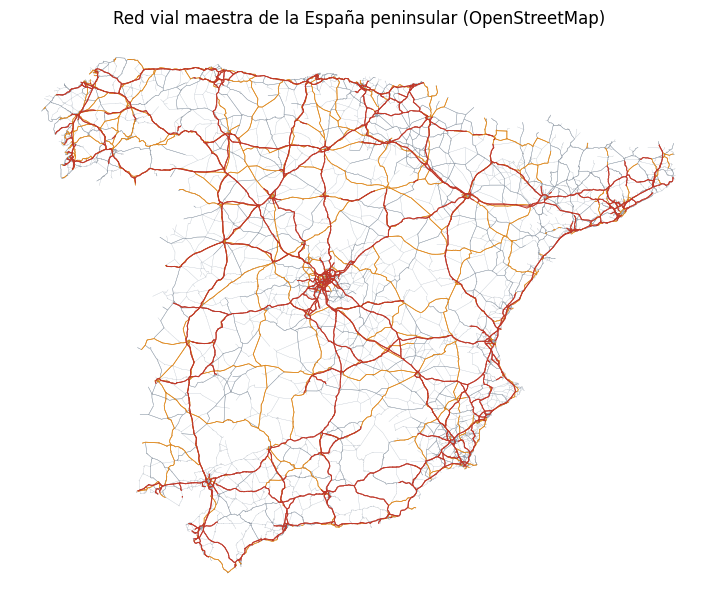

In [3]:
# Dibuja la red: rojo = autopista/autovía, naranja = vía rápida, gris = carretera principal, gris claro = secundaria
dibujar_red(G, titulo="Red vial maestra de la España peninsular (OpenStreetMap)")

**Fin de la Parte 1.** El grafo queda en la variable `G` (un `nx.MultiDiGraph` de NetworkX). En la Parte 2 se obtienen, filtrando aristas, las distintas versiones de la red de carreteras y los grafos de ciudades sobre los que se resolverá el problema del viajante.

---

## Parte 2. Versiones del grafo

<div style="border-left:5px solid #888;background:#F2F2F2;padding:10px 14px;margin:10px 0;border-radius:4px;">

**📋 ENUNCIADO**

A partir del grafo base de la Parte 1, obtener las **versiones** sobre las que se estudiará el Problema del Viajante. Una versión queda definida por cuatro elecciones:

- **Carreteras:** qué tipos de vía se pueden usar (todas, solo autovías, sin autovías...).
- **Ciudades:** qué ciudades hay que visitar (capitales de provincia, o también las de más de 100.000 habitantes; en toda España o por comunidad autónoma).
- **Peso:** qué se mide en cada tramo (kilómetros o tiempo).
- **Tipo de grafo:** dirigido o no dirigido, multigrafo o grafo simple.

Las versiones deben poder construirse de forma sencilla y cargarse con una sola línea desde las partes siguientes.

</div>

<div style="border-left:5px solid #4C72B0;background:#EEF2FA;padding:10px 14px;margin:10px 0;border-radius:4px;">

**📚 TEORÍA**

**Tabla de distancias.** Al viajante no le hace falta el mapa entero: solo cuánto cuesta ir de cada ciudad a cada otra por el mejor camino, como la tabla de distancias de un atlas de carreteras. Formalmente, dados el grafo de carreteras $G$ y un conjunto de ciudades $C$, la distancia entre dos ciudades $a, b \in C$ es

$$d(a,b)=\min_{P:\ a\to b}\ \sum_{e\in P} w(e),$$

el menor coste de un camino $P$ de $a$ a $b$, con $w(e)$ la longitud (en km) o el tiempo (en s) de cada arista $e$. Se calcula con el **algoritmo de Dijkstra**. El resultado es un **grafo completo de ciudades** $K=(C, C\times C, d)$: todas las ciudades unidas con todas.

**Dirigido o no dirigido.** En el grafo **dirigido** se respetan los sentidos únicos, así que $d(a,b)$ puede ser distinta de $d(b,a)$. En el **no dirigido** se ignoran los sentidos: cada tramo se puede recorrer en ambos sentidos con el menor de sus dos costes, y $d(a,b)=d(b,a)$. Por eso, el no dirigido nunca da distancias mayores que el dirigido.

**Multigrafo o grafo simple.** Si entre dos nodos hay varias aristas (un multigrafo), el camino mínimo solo usa la más barata. Quedarse con una sola (grafo simple) **no cambia ninguna distancia**.

**Ciudades que no están en la red.** Cada ciudad se asocia al nodo de carretera más cercano. Si una versión solo permite ciertas carreteras, una ciudad puede quedar muy lejos de la red (por ejemplo, de la red de autovías). Si la distancia al nodo más cercano supera un umbral $X$, la ciudad se **deja fuera** de esa versión y se registra, igual que las piezas de red desconectadas de la componente principal.

</div>

<div style="border-left:5px solid #8172B2;background:#F1EEF9;padding:10px 14px;margin:10px 0;border-radius:4px;">

**🔢 DATOS**

| Parámetro | Valores |
|---|---|
| **Carreteras** (`aristas`) | `completo` (8 tipos de vía) · `autovias_principales` (sin secundarias) · `solo_autovias` · `sin_autovias` |
| **Ciudades** (`nodos`) | `capitales` (47) · `capitales_y_100k` (75) |
| **Ámbito** (`ambito`) | `espana` o una de las 15 comunidades autónomas peninsulares |
| **Peso** (`peso`) | `km` (longitud, en km) · `tiempo` (el registrado en el grafo, en segundos) |
| **Tipo de grafo** (`general`) | `multigrafo_dirigido` · `grafo_dirigido` · `multigrafo_no_dirigido` · `grafo_simple_no_dirigido` |
| **Umbral de acceso** (`X_KM`) | 10 km |
| **Mínimo de ciudades por comunidad** (`N_MIN`) | 4 |

Los conjuntos de ciudades salen de `data/ciudades.csv` (47 capitales de provincia peninsulares y 28 municipios peninsulares de más de 100.000 habitantes que no son capitales; población del INE a 1/1/2025).

</div>

<div style="border-left:5px solid #55A868;background:#EAF6ED;padding:10px 14px;margin:10px 0;border-radius:4px;">

**🧮 RESOLUCIÓN**

**Idea.** Las distancias entre ciudades se calculan sobre **toda** la red de cada versión de carreteras, así que todas las versiones de ciudades (España, una comunidad...) son simplemente un **trozo de una misma tabla** de 75×75. Por eso solo hace falta calcular **16 tablas** (4 carreteras × 2 pesos × dirigido o no dirigido) y guardarlas en `data/versiones/`. Cada versión se obtiene después cogiendo de la tabla las ciudades que correspondan.

**Cálculo de las 16 tablas.** Para cada versión de carreteras: (1) se filtran las aristas por tipo de vía; (2) se conserva la mayor componente fuertemente conexa; (3) cada ciudad se asocia a su nodo más cercano y, si queda a más de `X_KM`, se deja fuera y se registra; (4) para cada peso y cada tipo de grafo se calculan con Dijkstra las distancias entre las ciudades que quedan.

**Decisiones.**
- **`multigrafo` y `grafo simple` dan la misma tabla** de ciudades (ver Teoría). La diferencia solo existe en el mapa de carreteras, así que `cargar_version` devuelve el mismo grafo de ciudades para ambos.
- **Bici y andando no son versiones aparte.** Con una velocidad constante, el tiempo es la distancia dividida por la velocidad, así que el camino más corto y el recorrido óptimo son los mismos que con los kilómetros. El caso «a pie o en bici» es `sin_autovias` con peso `km`; si se quieren horas, basta dividir (`km / 20` en bici, `km / 5` andando).
- **Las versiones por comunidad usan toda la red**, no solo las carreteras de esa comunidad: el mejor camino entre dos ciudades de la comunidad puede salir de ella.
- **Solo autovías:** algunas ciudades quedan a más de `X_KM` de la mayor componente de autovías y se dejan fuera (se registran en `excluidas.csv`). Como con las islas, en un primer intento no se puede plantear el viajante con ellas.

</div>

**💻 CÓDIGO**

**Parámetros de las versiones.** Son las variables que se pueden cambiar. Para volver a calcular las tablas con otro `X_KM` basta cambiarlo y poner `RECALCULAR = True`.

In [4]:
# ── Parámetros de las versiones (editables) ──
X_KM  = 10             # una ciudad a más de X_KM km de la red se deja fuera de la versión
N_MIN = 4              # mínimo de ciudades para una versión por comunidad autónoma
RECALCULAR = False     # True: vuelve a calcular las 16 tablas (necesita el grafo G de la Parte 1)
CARPETA = Path("data/versiones")     # aquí se guardan las tablas ya calculadas

# Qué tipos de vía (`highway`) puede usar cada versión de carreteras
CARRETERAS = {
    "completo":             ["motorway", "motorway_link", "trunk", "trunk_link",
                             "primary", "primary_link", "secondary", "secondary_link"],
    "autovias_principales": ["motorway", "motorway_link", "trunk", "trunk_link",
                             "primary", "primary_link"],
    "solo_autovias":        ["motorway", "motorway_link"],
    "sin_autovias":         ["trunk", "trunk_link", "primary", "primary_link",
                             "secondary", "secondary_link"],
}
PESOS = {"km": ("length", 1000), "tiempo": ("travel_time", 1)}   # peso -> (atributo de la arista, divisor)
CONJUNTOS = ["capitales", "capitales_y_100k"]                    # qué ciudades se visitan
GENERALES = ["multigrafo_dirigido", "grafo_dirigido",
             "multigrafo_no_dirigido", "grafo_simple_no_dirigido"]

**Ciudades.** Se leen de `data/ciudades.csv` y se definen los conjuntos de ciudades (por ejemplo, las capitales de Galicia).

In [5]:
# Lee la lista de ciudades (nombre, comunidad, si es capital de provincia, coordenadas...)
with open("data/ciudades.csv", encoding="utf-8") as f:
    CIUDADES = list(csv.DictReader(f))
for c in CIUDADES:
    c["lat"], c["lon"] = float(c["lat"]), float(c["lon"])
    c["capital"] = c["capital_provincia"] == "True"

def slug(texto):
    # "Castilla y León" -> "castilla_y_leon" (sin acentos ni espacios, para usarlo como nombre)
    sin_acentos = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return sin_acentos.lower().replace(" ", "_").replace("-", "_")

AMBITOS = ["espana"] + sorted({slug(c["comunidad"]) for c in CIUDADES})

def ciudades_de(nodos, ambito):
    # Nombres de las ciudades de un conjunto: nodos = "capitales" o "capitales_y_100k";
    # ambito = "espana" o una comunidad (p. ej. "galicia")
    return [c["nombre"] for c in CIUDADES
            if (c["capital"] or nodos == "capitales_y_100k")
            and (ambito == "espana" or slug(c["comunidad"]) == ambito)]

print(f"{len(CIUDADES)} ciudades | {len(ciudades_de('capitales', 'espana'))} capitales | ámbitos: {len(AMBITOS) - 1} comunidades")
print("Capitales de Galicia:", ciudades_de("capitales", "galicia"))

75 ciudades | 47 capitales | ámbitos: 15 comunidades
Capitales de Galicia: ['A Coruña', 'Ourense', 'Lugo', 'Pontevedra']


**Funciones para calcular una tabla de distancias.** Tres pasos: filtrar las carreteras, asociar cada ciudad a su nodo más cercano y calcular las distancias con Dijkstra.

In [6]:
def filtrar_aristas(G, tipos):
    # Red con solo las aristas de los tipos de vía indicados, quedándose con la mayor
    # componente fuertemente conexa (así se puede ir de cualquier nodo a cualquier otro)
    aristas = [(u, v, k) for u, v, k, d in G.edges(keys=True, data=True) if d["highway"] in tipos]
    H = G.edge_subgraph(aristas)
    nodos_antes = H.number_of_nodes()
    mayor = max(nx.strongly_connected_components(H), key=len)
    H = H.subgraph(mayor).copy()
    informe = {"nodos": H.number_of_nodes(), "n_aristas": H.number_of_edges(),
               "km": round(sum(d["length"] for _, _, d in H.edges(data=True)) / 1000),
               "nodos_descartados": nodos_antes - H.number_of_nodes()}
    return H, informe

In [7]:
KM_LON = 111.32 * np.cos(np.radians(40.4))   # km por grado de longitud (a la latitud de España)
KM_LAT = 110.57                               # km por grado de latitud

def asociar_ciudades(H, ciudades, x_km):
    # Asocia cada ciudad al nodo de carretera más cercano. Si está a más de x_km, la ciudad
    # queda fuera de la versión y se registra con su distancia.
    nodos = list(H.nodes)
    puntos = np.array([[H.nodes[n]["x"] * KM_LON, H.nodes[n]["y"] * KM_LAT] for n in nodos])
    arbol = cKDTree(puntos)                    # estructura para buscar el punto más cercano
    asociacion, excluidas = {}, []
    for c in ciudades:
        distancia, i = arbol.query([c["lon"] * KM_LON, c["lat"] * KM_LAT])
        if distancia <= x_km:
            asociacion[c["nombre"]] = nodos[i]
        else:
            excluidas.append((c["nombre"], round(float(distancia), 1)))
    return asociacion, excluidas

In [8]:
def tabla_distancias(H, asociacion, peso, dirigido):
    # Tabla ciudades x ciudades con el camino mínimo entre cada par (algoritmo de Dijkstra).
    # peso: "km" o "tiempo". Si no es dirigido, se ignoran los sentidos únicos.
    atributo, divisor = PESOS[peso]
    nodos = list(H.nodes)
    indice = {n: i for i, n in enumerate(nodos)}
    mejor = {}                                 # arista más barata entre cada par de nodos (grafo simple)
    for u, v, d in H.edges(data=True):
        for par in ([(u, v)] if dirigido else [(u, v), (v, u)]):
            if par not in mejor or d[atributo] < mejor[par]:
                mejor[par] = d[atributo]
    filas = [indice[u] for u, v in mejor]
    columnas = [indice[v] for u, v in mejor]
    M = csr_matrix((list(mejor.values()), (filas, columnas)), shape=(len(nodos), len(nodos)))
    origenes = [indice[asociacion[c]] for c in asociacion]
    D = dijkstra(M, directed=True, indices=origenes)[:, origenes]    # solo las columnas de las ciudades
    return D / divisor

**Guardar y leer las tablas.** Se guardan como CSV (se pueden abrir con Excel) con el nombre de las ciudades en la primera fila.

In [9]:
def nombre_tabla(aristas, peso, dirigido):
    return CARPETA / f"{aristas}__{peso}__{'dirigido' if dirigido else 'no_dirigido'}.csv"

def guardar_tabla(D, nombres, ruta):
    with open(ruta, "w", encoding="utf-8") as f:
        np.savetxt(f, D, delimiter=",", header=",".join(nombres), comments="", fmt="%.3f")

def leer_tabla(aristas, peso, dirigido):
    ruta = nombre_tabla(aristas, peso, dirigido)
    with open(ruta, encoding="utf-8") as f:
        nombres = f.readline().strip().split(",")        # primera fila: nombres de las ciudades
    return np.loadtxt(ruta, delimiter=",", skiprows=1, encoding="utf-8"), nombres

def escribir_csv(ruta, filas, campos):
    with open(ruta, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=campos)
        w.writeheader()
        w.writerows(filas)

**Calcular las 16 tablas** (4 carreteras × 2 pesos × dirigido o no dirigido). Solo se ejecuta si todavía no existen (o si `RECALCULAR = True`) y necesita el grafo `G` de la Parte 1. Tarda unos minutos.

In [10]:
def construir_tablas(G):
    CARPETA.mkdir(parents=True, exist_ok=True)
    resumen, registro = [], []
    for aristas, tipos in CARRETERAS.items():
        H, informe = filtrar_aristas(G, tipos)
        asociacion, excluidas = asociar_ciudades(H, CIUDADES, X_KM)
        for peso in PESOS:
            for dirigido in (True, False):
                D = tabla_distancias(H, asociacion, peso, dirigido)
                guardar_tabla(D, list(asociacion), nombre_tabla(aristas, peso, dirigido))
        resumen.append({"carreteras": aristas, **informe, "ciudades_fuera": len(excluidas)})
        registro += [{"carreteras": aristas, "ciudad": c, "distancia_km": d} for c, d in excluidas]
        print(f"{aristas:22s} {informe['nodos']:6d} nodos | {len(excluidas)} ciudades fuera")
    escribir_csv(CARPETA / "resumen_carreteras.csv", resumen,
                 ["carreteras", "nodos", "n_aristas", "km", "nodos_descartados", "ciudades_fuera"])
    escribir_csv(CARPETA / "excluidas.csv", registro, ["carreteras", "ciudad", "distancia_km"])

tablas_hechas = all(nombre_tabla(a, p, d).exists() for a in CARRETERAS for p in PESOS for d in (True, False))
if RECALCULAR or not tablas_hechas:
    construir_tablas(G)
else:
    print("Las 16 tablas ya están calculadas en", CARPETA, "(RECALCULAR = True para volver a calcularlas)")

Las 16 tablas ya están calculadas en data\versiones (RECALCULAR = True para volver a calcularlas)


**Cargar una versión.** `cargar_version` devuelve el grafo de ciudades `K` de la versión pedida: un grafo de NetworkX cuyos nodos son las ciudades y donde `K[a][b]["peso"]` es la distancia de `a` a `b`. Es lo que usarán los algoritmos de la Parte 3.

In [11]:
UNIDAD = {"km": "km", "tiempo": "segundos"}

def cargar_version(aristas, nodos, ambito, peso, general):
    # aristas: "completo" | "autovias_principales" | "solo_autovias" | "sin_autovias"
    # nodos:   "capitales" | "capitales_y_100k"       ambito: "espana" | "galicia" | "andalucia" ...
    # peso:    "km" | "tiempo"                        general: uno de GENERALES
    # (multigrafo y grafo simple dan el mismo grafo de ciudades: no hay aristas repetidas)
    dirigido = "no_dirigido" not in general
    D, nombres = leer_tabla(aristas, peso, dirigido)
    elegidas = [c for c in ciudades_de(nodos, ambito) if c in nombres]    # sin las que quedaron fuera
    if ambito != "espana" and len(elegidas) < N_MIN:
        raise ValueError(f"Solo hay {len(elegidas)} ciudades (mínimo {N_MIN}) en {ambito}")
    K = nx.DiGraph() if dirigido else nx.Graph()
    for c in CIUDADES:
        if c["nombre"] in elegidas:
            K.add_node(c["nombre"], lat=c["lat"], lon=c["lon"])
    for p, a in enumerate(elegidas):
        for q, b in enumerate(elegidas):
            if p != q and (dirigido or p < q):                            # no dirigido: una arista por par
                K.add_edge(a, b, peso=float(D[nombres.index(a), nombres.index(b)]))
    K.graph.update(aristas=aristas, nodos=nodos, ambito=ambito, peso=peso,
                   unidad=UNIDAD[peso], general=general,
                   fuera=[c for c in ciudades_de(nodos, ambito) if c not in nombres])
    return K

**Catálogo de versiones.** Lista de todas las versiones válidas (una por combinación de parámetros); se guarda en `data/versiones/catalogo.csv`.

In [12]:
def catalogo():
    # Todas las versiones válidas: las de España siempre; las de una comunidad solo si
    # tienen al menos N_MIN ciudades (después de dejar fuera las que quedan a más de X_KM)
    en_version = {a: leer_tabla(a, "km", True)[1] for a in CARRETERAS}    # ciudades que hay en cada versión de carreteras
    versiones = []
    for aristas, nodos, ambito, peso, general in itertools.product(CARRETERAS, CONJUNTOS, AMBITOS, PESOS, GENERALES):
        n = len([c for c in ciudades_de(nodos, ambito) if c in en_version[aristas]])
        if ambito == "espana" or n >= N_MIN:
            versiones.append({"aristas": aristas, "nodos": nodos, "ambito": ambito, "peso": peso,
                              "general": general, "n_ciudades": n})
    return versiones

VERSIONES = catalogo()
escribir_csv(CARPETA / "catalogo.csv", VERSIONES, list(VERSIONES[0]))
print(f"{len(VERSIONES)} versiones en el catálogo | ejemplos:")
for v in VERSIONES[:2] + VERSIONES[-2:]:
    print("  ", v)

480 versiones en el catálogo | ejemplos:
   {'aristas': 'completo', 'nodos': 'capitales', 'ambito': 'espana', 'peso': 'km', 'general': 'multigrafo_dirigido', 'n_ciudades': 47}
   {'aristas': 'completo', 'nodos': 'capitales', 'ambito': 'espana', 'peso': 'km', 'general': 'grafo_dirigido', 'n_ciudades': 47}
   {'aristas': 'sin_autovias', 'nodos': 'capitales_y_100k', 'ambito': 'pais_vasco', 'peso': 'tiempo', 'general': 'multigrafo_no_dirigido', 'n_ciudades': 4}
   {'aristas': 'sin_autovias', 'nodos': 'capitales_y_100k', 'ambito': 'pais_vasco', 'peso': 'tiempo', 'general': 'grafo_simple_no_dirigido', 'n_ciudades': 4}


**Ver qué quedó en cada versión de carreteras.** El tamaño de cada red y las ciudades que quedaron fuera por estar a más de `X_KM` de ella.

In [13]:
with open(CARPETA / "resumen_carreteras.csv", encoding="utf-8") as f:
    resumen = list(csv.DictReader(f))
print(f"{'versión de carreteras':22s} {'nodos':>7s} {'aristas':>8s} {'km':>8s} {'nodos descartados':>18s} {'ciudades fuera':>15s}")
for r in resumen:
    print(f"{r['carreteras']:22s} {r['nodos']:>7s} {r['n_aristas']:>8s} {r['km']:>8s} {r['nodos_descartados']:>18s} {r['ciudades_fuera']:>15s}")

with open(CARPETA / "excluidas.csv", encoding="utf-8") as f:
    excluidas = list(csv.DictReader(f))
print(f"\nCiudades dejadas fuera (a más de {X_KM} km de la red):")
for r in excluidas:
    print(f"  {r['carreteras']:14s} {r['ciudad']:12s} {r['distancia_km']:>6s} km")

versión de carreteras    nodos  aristas       km  nodos descartados  ciudades fuera
completo                179594   309250   182760                  0               0
autovias_principales    115476   190221   111121               5885               0
solo_autovias            19239    24450    28921              14027               3
sin_autovias            146903   256301   140040               8464               0

Ciudades dejadas fuera (a más de 10 km de la red):
  solo_autovias  Badajoz        50.5 km
  solo_autovias  Salamanca      62.7 km
  solo_autovias  Cuenca         39.6 km


**Ejemplo de uso.** Pedir dos versiones distintas y consultar una distancia.

In [14]:
K = cargar_version(aristas="completo", nodos="capitales", ambito="espana", peso="km", general="grafo_dirigido")
print(K)
print(f"Madrid → Sevilla: {K['Madrid']['Sevilla']['peso']:.0f} km | Sevilla → Madrid: {K['Sevilla']['Madrid']['peso']:.0f} km")

K2 = cargar_version(aristas="sin_autovias", nodos="capitales_y_100k", ambito="galicia", peso="tiempo",
                    general="grafo_simple_no_dirigido")
print(K2, "| ciudades:", list(K2.nodes))
print(f"Vigo – Santiago de Compostela: {K2['Vigo']['Santiago de Compostela']['peso'] / 3600:.2f} horas (tiempo registrado, de coche)")

DiGraph with 47 nodes and 2162 edges
Madrid → Sevilla: 502 km | Sevilla → Madrid: 517 km
Graph with 6 nodes and 15 edges | ciudades: ['A Coruña', 'Ourense', 'Lugo', 'Pontevedra', 'Vigo', 'Santiago de Compostela']
Vigo – Santiago de Compostela: 1.83 horas (tiempo registrado, de coche)


**Comprobaciones.** Propiedades que tienen que cumplir las tablas calculadas.

In [15]:
TOL = 0.01      # las tablas se guardan con 3 decimales: tolerancia de redondeo
for aristas in CARRETERAS:
    for peso in PESOS:
        Dd, nombres = leer_tabla(aristas, peso, True)       # red dirigida
        Dn, _ = leer_tabla(aristas, peso, False)            # red no dirigida
        assert np.all(np.isfinite(Dd)) and np.all(Dd >= 0), "distancias infinitas o negativas"
        assert np.allclose(np.diag(Dd), 0), "la distancia de una ciudad a sí misma debe ser 0"
        assert np.allclose(Dn, Dn.T, atol=TOL), "la tabla no dirigida debe ser simétrica"
        assert np.all(Dn <= Dd + TOL), "ignorar los sentidos nunca puede alargar una distancia"
        # desigualdad triangular: ir de i a k nunca es más largo que pasar por j
        assert np.all(Dd[:, None, :] <= Dd[:, :, None] + Dd[None, :, :] + TOL), "falla la desigualdad triangular"
print("Todas las tablas cumplen las comprobaciones.")

Todas las tablas cumplen las comprobaciones.


**Fin de la Parte 2.** Con `cargar_version(...)` se obtiene el grafo de ciudades `K` de cualquiera de las versiones del catálogo. En la Parte 3 se explican los algoritmos para el Problema del Viajante y se programan para trabajar sobre `K`.

---